<a href="https://colab.research.google.com/github/karthika12454/karthika/blob/main/dl_unit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files

uploaded = files.upload()

import io
import pandas as pd
import numpy as np

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv
Dataset loaded successfully!
Shape: (111, 60)

First 5 rows:


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68



Column names:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


In [2]:

%pip install -q tensorflow scikit-learn matplotlib

import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [4]:

import pandas as pd
import numpy as np

df = df.dropna(how="all").dropna(axis=1, how="all")


df.columns = df.columns.astype(str).str.strip()


country_name = "US"

country_row = df[
    df["Country"].astype(str).str.strip() == country_name
]

if country_row.empty:
    raise ValueError("US country not found in the dataset.")

year_columns = [
    col for col in df.columns
    if col.isdigit() and len(col) == 4
]

if not year_columns:
    raise ValueError("Year columns were not found.")

data = country_row[["Country"] + year_columns].melt(
    id_vars=["Country"],
    var_name="year",
    value_name="energy_consumption"
)

data["year"] = pd.to_numeric(data["year"], errors="coerce")
data["energy_consumption"] = pd.to_numeric(
    data["energy_consumption"], errors="coerce"
)

data = data.dropna(
    subset=["year", "energy_consumption"]
)

data = data.sort_values("year").reset_index(drop=True)

print("Selected country:", country_name)
print("Total yearly records:", len(data))
display(data.head())
display(data.tail())


Selected country: US
Total yearly records: 59


,Country,year,energy_consumption
0,US,1965,51.98
1,US,1966,54.89
2,US,1967,56.80
3,US,1968,60.19
4,US,1969,63.30


,Country,year,energy_consumption
54,US,2019,95.68
55,US,2020,88.64
56,US,2021,93.44
57,US,2022,95.42
58,US,2023,94.28


In [5]:

from sklearn.preprocessing import MinMaxScaler

values = data["energy_consumption"].values.reshape(-1, 1)

split_index = int(len(values) * 0.8)

scaler = MinMaxScaler()
scaler.fit(values[:split_index])

scaled_values = scaler.transform(values)

print("Training records:", split_index)
print("Testing records:", len(values) - split_index)
print("Normalized data shape:", scaled_values.shape)


Training records: 47
Testing records: 12
Normalized data shape: (59, 1)


In [6]:

TIME_STEPS = 5

X_train, y_train = [], []
X_test, y_test = [], []

for i in range(TIME_STEPS, split_index):
    X_train.append(scaled_values[i-TIME_STEPS:i])
    y_train.append(scaled_values[i])

for i in range(split_index, len(scaled_values)):
    X_test.append(scaled_values[i-TIME_STEPS:i])
    y_test.append(scaled_values[i])

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (42, 5, 1)
y_train: (42, 1)
X_test: (12, 5, 1)
y_test: (12, 1)


In [7]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(TIME_STEPS, 1)),
    LSTM(32, activation="tanh"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training completed!")


Epoch 1/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - loss: 0.3342 - val_loss: 0.6843
Epoch 2/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.2788 - val_loss: 0.5798
Epoch 3/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.2273 - val_loss: 0.4803
Epoch 4/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1835 - val_loss: 0.3838
Epoch 5/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1384 - val_loss: 0.2830
Epoch 6/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0977 - val_loss: 0.1894
Epoch 7/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0663 - val_loss: 0.1081
Epoch 8/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0262 - val_loss: 0.0475
Epoch 9/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0125 - val_loss: 0.0118
Epoch 10/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0140 - val_loss: 0.0029
Epoch 11/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0181 - val_loss: 0.0068
Epoch 12/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0230 - val_lo

In [8]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

pred_scaled = model.predict(X_test, verbose=0)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(pred_scaled)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")


MAE: 1.5858
RMSE: 2.2962


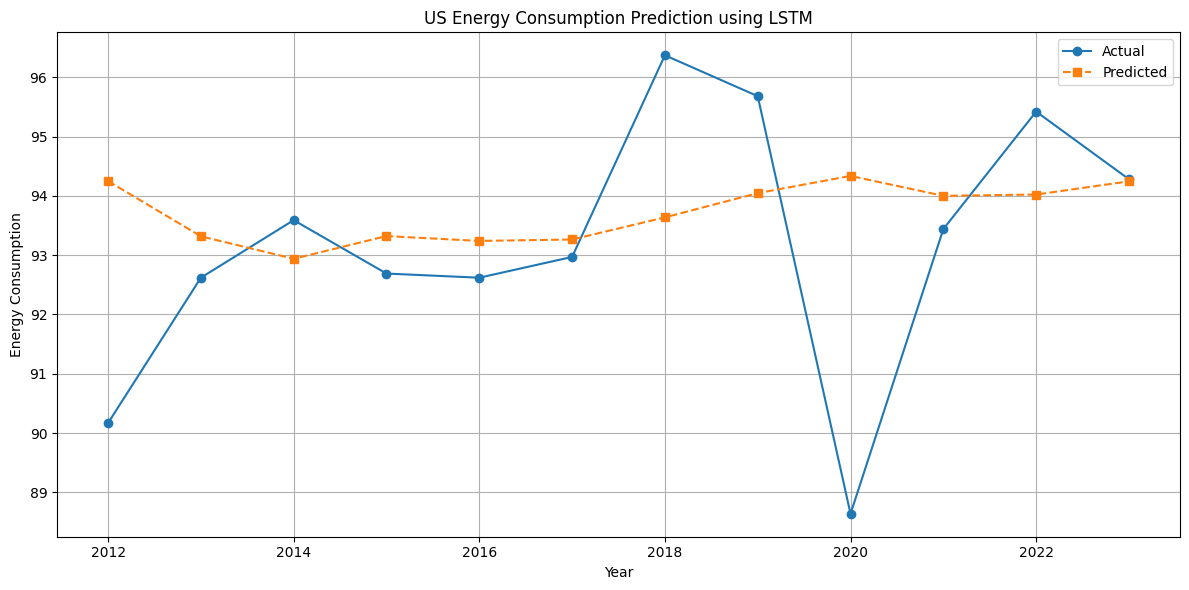

,Year,Actual,Predicted
0,2012,90.17,94.249001
1,2013,92.62,93.318001
2,2014,93.59,92.939003
3,2015,92.69,93.321999
4,2016,92.62,93.239998
5,2017,92.97,93.264000
6,2018,96.37,93.638000
7,2019,95.68,94.045998
8,2020,88.64,94.335999
9,2021,93.44,94.000000


In [9]:

import matplotlib.pyplot as plt

test_years = data["year"].values[split_index:]

plt.figure(figsize=(12, 6))
plt.plot(test_years, actual.flatten(),
         marker="o", label="Actual")
plt.plot(test_years, predicted.flatten(),
         marker="s", linestyle="--", label="Predicted")

plt.title("US Energy Consumption Prediction using LSTM")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

results = pd.DataFrame({
    "Year": test_years.astype(int),
    "Actual": actual.flatten(),
    "Predicted": predicted.flatten()
})

display(results.round(3))


In [10]:

last_sequence = scaled_values[-TIME_STEPS:].reshape(1, TIME_STEPS, 1)

next_scaled = model.predict(last_sequence, verbose=0)
next_value = scaler.inverse_transform(next_scaled)[0, 0]

print("Country: US")
print("Last available year:", int(data["year"].iloc[-1]))
print("Predicted year:", int(data["year"].iloc[-1]) + 1)
print("Predicted energy consumption:", round(float(next_value), 3))


Country: US
Last available year: 2023
Predicted year: 2024
Predicted energy consumption: 93.968


In [11]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
pred_scaled = model.predict(X_test, verbose=0)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(pred_scaled)
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = np.mean(
    np.abs((actual.flatten() - predicted.flatten()) /
           np.maximum(np.abs(actual.flatten()), 1e-8))
) * 100

accuracy = max(0, 100 - mape)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("MAPE:", round(mape, 2), "%")
print("Approximate forecast accuracy:", round(accuracy, 2), "%")


MAE: 1.5858
RMSE: 2.2962
MAPE: 1.73 %
Approximate forecast accuracy: 98.27 %


In [12]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

pred_scaled = model.predict(X_test, verbose=0)

actual = scaler.inverse_transform(y_test).flatten()
predicted = scaler.inverse_transform(pred_scaled).flatten()

mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)

mape = np.mean(
    np.abs((actual - predicted) /
           np.maximum(np.abs(actual), 1e-8))
) * 100

print("========== EVALUATION METRICS ==========")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.2f}%")
print("========================================")


========== EVALUATION METRICS ==========
MAE  : 1.5858
MSE  : 5.2723
RMSE : 2.2962
MAPE : 1.73%
